# Train your PyTorch DDP model

To download this notebook visit this [link](https://github.com/SETU-AIML-2026/DH-Infra-AI/blob/main/topic-04-sprint-3-AI/unit-3-hpc/notebook-1-ddpt/lab9.ipynb)

This notebook packages the `src/train.py` into a Docker image and submits a **single-worker Vertex AI CustomJob** in `europe-west1` with **two NVIDIA T4 GPUs**.

**Before running:** edit the configuration cell with your Google Cloud project ID and the name of the existing GCS bucket containing:

- `gs://YOUR_BUCKET/sharded/train.csv`
- `gs://YOUR_BUCKET/sharded/dev.csv`

The notebook keeps the data in GCS. It builds the container remotely with Cloud Build, pushes it to Artifact Registry, then submits the Vertex AI job.


**IMPORTANT: you need to increas your T4 GPU quota for the region that we are using**

Visit https://console.cloud.google.com/iam-admin/quotas to submit your request.
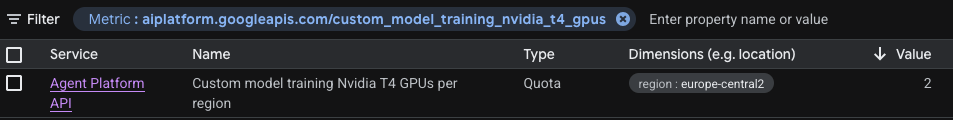

## 1. Configure your Google Cloud project and training

In [ ]:
!pip install google-cloud-aiplatform

In [ ]:
# EDIT THESE VALUES
PROJECT_ID = "dh-inf-for-ai"
REGION = "europe-west1"
BUCKET_NAME = "titanic-dh-data"

REPOSITORY = "ml-training"
IMAGE_NAME = "titanic-ddp"
DISPLAY_NAME = "titanic-ddp-2xt4"

# Start with a short smoke test. Change to 100 after it succeeds.
EPOCHS = 2
HIDDEN_SIZE = 1000
BATCH_SIZE = 64
LEARNING_RATE = 0.001

MACHINE_TYPE = "n1-standard-8"
ACCELERATOR_TYPE = "NVIDIA_TESLA_T4"
ACCELERATOR_COUNT = 2

IMAGE_URI = (
    f"{REGION}-docker.pkg.dev/"
    f"{PROJECT_ID}/{REPOSITORY}/{IMAGE_NAME}:latest"
)

assert PROJECT_ID != "YOUR_GOOGLE_CLOUD_PROJECT_ID", "Set PROJECT_ID first."
assert BUCKET_NAME != "YOUR_EXISTING_GCS_BUCKET", "Set BUCKET_NAME first."

print("Container image:", IMAGE_URI)
print("Training data:", f"gs://{BUCKET_NAME}/sharded/")
print("Target:", REGION, MACHINE_TYPE, f"{ACCELERATOR_COUNT} x {ACCELERATOR_TYPE}")


## 2. Authenticate Colab and enable required APIs

In [ ]:
from google.colab import auth
auth.authenticate_user()

!gcloud config set project {PROJECT_ID}
!gcloud services enable aiplatform.googleapis.com
!gcloud services enable  artifactregistry.googleapis.com
!gcloud services enable cloudbuild.googleapis.com


In [ ]:
STAGING_BUCKET = f"{PROJECT_ID}-vertex-staging-europe-west1"

!gcloud storage buckets create gs://{STAGING_BUCKET} --location=europe-west1 --uniform-bucket-level-access

## 3. Verify that the existing training data is present

In [ ]:
!gcloud storage ls gs://{BUCKET_NAME}/sharded/train.csv
!gcloud storage ls gs://{BUCKET_NAME}/sharded/dev.csv


## 4. Create the training source, dependencies, and Dockerfile

In [ ]:
import os

# Create a directory to store our training script
os.makedirs('src', exist_ok=True)


In [ ]:
%%writefile src/train.py
import os
import argparse
import pandas as pd
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
import torch.distributed as dist
from torch.nn.parallel import DistributedDataParallel as DDP
from torch.utils.data import DataLoader, TensorDataset
from torch.utils.data.distributed import DistributedSampler
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score
from google.cloud import storage

# Set random seed
NN_RANDOM_STATE = 42
torch.manual_seed(NN_RANDOM_STATE)
np.random.seed(NN_RANDOM_STATE)

# Define Model
class TitanicMLP(nn.Module):
    def __init__(self, input_size, hidden_size):
        super(TitanicMLP, self).__init__()
        self.network = nn.Sequential(
            nn.Linear(input_size, hidden_size),
            nn.Sigmoid(),
            nn.Linear(hidden_size, hidden_size),
            nn.Sigmoid(),
            nn.Linear(hidden_size, hidden_size),
            nn.Sigmoid(),
            nn.Linear(hidden_size, 1),
        )

    def forward(self, x):
        return self.network(x)

def preprocess_split(df_split, df_train):
    features = ['Pclass', 'Age', 'SibSp', 'Parch', 'Fare', 'Sex', 'Embarked']
    df_processed = df_split[features].copy()
    df_processed['Age'].fillna(df_train['Age'].median())
    df_processed['Fare'].fillna(df_train['Fare'].median())
    df_processed['Embarked'].fillna(df_train['Embarked'].mode()[0])
    df_processed = pd.get_dummies(df_processed, columns=['Sex', 'Embarked'], drop_first=True)
    expected_columns = ['Pclass', 'Age', 'SibSp', 'Parch', 'Fare', 'Sex_male', 'Embarked_Q', 'Embarked_S']
    for col in expected_columns:
        if col not in df_processed.columns:
            df_processed[col] = 0
    return df_processed[expected_columns]

if __name__ == '__main__':
    parser = argparse.ArgumentParser()
    parser.add_argument('--bucket_name', type=str, required=True)
    parser.add_argument('--hidden_size', type=int, default=1000)
    parser.add_argument('--epochs', type=int, default=100)
    parser.add_argument('--batch_size', type=int, default=64)
    parser.add_argument('--lr', type=float, default=0.001)
    args = parser.parse_args()

    # Initialize Distributed Process Group
    dist.init_process_group(backend='nccl')

    # Get rank info
    local_rank = int(os.environ["LOCAL_RANK"])
    global_rank = int(os.environ["RANK"])
    world_size = int(os.environ["WORLD_SIZE"])

    # Set device according to local rank allocation
    torch.cuda.set_device(local_rank)
    device = torch.device('cuda', local_rank)

    # 1. Load Data
    train_url = f"gs://{args.bucket_name}/sharded/train.csv"
    dev_url = f"gs://{args.bucket_name}/sharded/dev.csv"
    df_train = pd.read_csv(train_url)
    df_dev = pd.read_csv(dev_url)

    # 2. Preprocess & Scale
    X_train = preprocess_split(df_train, df_train)
    y_train = df_train['Survived']
    X_test = preprocess_split(df_dev, df_train)
    y_test = df_dev['Survived']

    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train)
    X_test_scaled = scaler.transform(X_test)

    # 3. Build Tensors
    X_tr_t = torch.FloatTensor(X_train_scaled.astype(np.float32)).to(device)
    y_tr_t = torch.FloatTensor(np.array(y_train).astype(np.float32)).unsqueeze(1).to(device)
    X_te_t = torch.FloatTensor(X_test_scaled.astype(np.float32)).to(device)
    dataset = TensorDataset(X_tr_t, y_tr_t)

    # Use DistributedSampler to shard datasets across processes
    sampler = DistributedSampler(dataset, num_replicas=world_size, rank=global_rank, shuffle=True)
    loader = DataLoader(dataset, batch_size=args.batch_size, sampler=sampler)

    # Create Model and Wrap with DDP
    model = TitanicMLP(X_train_scaled.shape[1], args.hidden_size).to(device)
    model = DDP(model, device_ids=[local_rank], output_device=local_rank)

    criterion = nn.BCEWithLogitsLoss()
    optimizer = optim.Adam(model.parameters(), lr=args.lr)

    # 4. Train
    model.train()
    for epoch in range(args.epochs):
        sampler.set_epoch(epoch)  # Shuffle data differently across epochs
        for batch_x, batch_y in loader:
            optimizer.zero_grad()
            outputs = model(batch_x)
            loss = criterion(outputs, batch_y)
            loss.backward()
            optimizer.step()

    # 5. Evaluate
    model.eval()
    with torch.no_grad():
        predictions = torch.sigmoid(model(X_te_t)).cpu().numpy()
        predictions = (predictions > 0.5).astype(int)
        acc = accuracy_score(y_test, predictions)

    if global_rank == 0:
        print(f"Training complete. Validation Accuracy: {acc:.4f}")

        # 6. Save Model Locally and Upload to GCS from master node (rank 0)
        local_model_path = 'model.pt'
        torch.save(model.module.state_dict(), local_model_path)

        client = storage.Client()
        bucket = client.bucket(args.bucket_name)
        blob = bucket.blob('model/model.pt')
        blob.upload_from_filename(local_model_path)
        print(f"Model successfully exported to gs://{args.bucket_name}/model/model.pt")

    # Clean up process group
    dist.destroy_process_group()

In [ ]:
# Run a local smoke test using torchrun
# This automatically sets up the RANK, WORLD_SIZE, and LOCAL_RANK variables.
!torchrun --standalone --nnodes=1 --nproc_per_node=1 src/train.py \
    --bucket_name {BUCKET_NAME} \
    --hidden_size {HIDDEN_SIZE} \
    --epochs {EPOCHS} \
    --batch_size {BATCH_SIZE} \
    --lr {LEARNING_RATE}

In [ ]:
requirements = 'pandas\nnumpy\nscikit-learn\ngoogle-cloud-storage\ngcsfs\n'
with open("requirements.txt", "w", encoding="utf-8") as f:
    f.write(requirements)

dockerfile = """FROM pytorch/pytorch:2.5.1-cuda12.4-cudnn9-runtime

WORKDIR /app

RUN pip install --no-cache-dir \\
    pandas \\
    numpy \\
    scikit-learn \\
    google-cloud-storage \\
    gcsfs

COPY src/ ./src/

ENTRYPOINT ["torchrun", "--standalone", "--nnodes=1", "--nproc_per_node=2", "src/train.py"]
"""

with open("Dockerfile", "w", encoding="utf-8") as f:
    f.write(dockerfile)

print("Created requirements.txt and Dockerfile")


## 5. Create the Artifact Registry repository (if it does not already exist)

In [ ]:
import subprocess

describe_cmd = [
    "gcloud", "artifacts", "repositories", "describe", REPOSITORY,
    f"--location={REGION}", "--project", PROJECT_ID
]
result = subprocess.run(describe_cmd, capture_output=True, text=True)

if result.returncode == 0:
    print(f"Artifact Registry repository {REPOSITORY!r} already exists.")
else:
    create_cmd = [
        "gcloud", "artifacts", "repositories", "create", REPOSITORY,
        "--repository-format=docker",
        f"--location={REGION}",
        "--project", PROJECT_ID,
        "--description=Container images for ML training"
    ]
    subprocess.run(create_cmd, check=True)


## 6. Build and push the container with Cloud Build

In [ ]:
!gcloud builds submit . --project={PROJECT_ID} --tag={IMAGE_URI}


## 7. Submit the Vertex AI CustomJob

The container entrypoint runs `torchrun --nproc_per_node=2`. The arguments below are passed to your `train.py`. One replica means **one VM with two attached GPUs**, not two VMs.

**Service account / GCS access:** the job needs an execution identity that can read the two CSVs and create `model/model.pt` in your bucket. The SDK uses Vertex AI's default execution identity if `service_account` is omitted. Ensure that identity has access to the bucket before submitting. If your organization requires a specific service account, set `JOB_SERVICE_ACCOUNT` below and grant it the bucket permissions.


In [ ]:
# Optional: set this to a service account email if your project requires a
# user-managed execution service account. Leave as None to use the platform default.
JOB_SERVICE_ACCOUNT = None

from google.cloud import aiplatform

aiplatform.init(
    project=PROJECT_ID,
    location=REGION,
    staging_bucket=f"gs://{STAGING_BUCKET}",
)

worker_pool_specs = [
    {
        "machine_spec": {
            "machine_type": MACHINE_TYPE,
            "accelerator_type": ACCELERATOR_TYPE,
            "accelerator_count": ACCELERATOR_COUNT,
        },
        "replica_count": 1,
        "container_spec": {
            "image_uri": IMAGE_URI,
            "args": [
                "--bucket_name", BUCKET_NAME,
                "--hidden_size", str(HIDDEN_SIZE),
                "--epochs", str(EPOCHS),
                "--batch_size", str(BATCH_SIZE),
                "--lr", str(LEARNING_RATE),
            ],
        },
    }
]

job_kwargs = {
    "display_name": DISPLAY_NAME,
    "worker_pool_specs": worker_pool_specs,
}
if JOB_SERVICE_ACCOUNT:
    job_kwargs["service_account"] = JOB_SERVICE_ACCOUNT

job = aiplatform.CustomJob(**job_kwargs)
job.run(sync=False, timeout=300)

# Wait until Vertex AI has created the job resource
job.wait_for_resource_creation()

print("Submitted Vertex AI job:", job.resource_name)


## 8. Monitor the job

In [ ]:
print("Job resource:", job.resource_name)
print("Current state:", job.state)
# You can also open Vertex AI > Training > Custom jobs in Google Cloud Console.

In [ ]:
#To check the logs:
job_id = job.resource_name.split("/")[-1]

!gcloud logging read \
  'resource.type="ml_job" AND resource.labels.job_id="{job_id}"' \
  --project={PROJECT_ID} \
  --order=asc \
  --limit=1000 \
  --format="value(timestamp,severity,textPayload)"

In [ ]:
#To list all jobs (you might need to delete some stuck ones)
!gcloud ai custom-jobs list \
    --project={PROJECT_ID} \
    --region=europe-west1 \
    --format="table(name,displayName,state,createTime)"
# you can also use the ui at https://console.cloud.google.com/agent-platform/training/custom-jobs

## 9. Expected output
The training script uploads the trained weights from rank 0 to:

`gs://YOUR_BUCKET/model/model.pt`

After the job succeeds, verify the object:

```bash
gcloud storage ls gs://YOUR_BUCKET/model/model.pt
```


### Troubleshooting checklist

- **Quota / capacity error:** confirm regional `NVIDIA_T4_GPUS` quota and T4 capacity in `europe-west1`. A valid machine configuration does not guarantee immediate capacity.
- **GCS permission error:** grant the job's execution service account permission to read the bucket objects and create the output object. For this script, `Storage Object Viewer` plus `Storage Object Creator` on the bucket is a reasonable starting point.
- **`gcsfs` / ADC error:** confirm the Vertex AI job is running under an identity with access to the bucket.
- **NCCL / CUDA error:** check that the container has access to both GPUs and that the logs show two `torchrun` processes.
- **Container build error:** inspect the Cloud Build build log; make sure the Colab working directory contains `Dockerfile` and `src/train.py`.
